# 3. Модели

Третий ноутбук проекта. Здесь мы обучаем и сравниваем модели, которые по данным одной госпитализации предсказывают, вернётся ли пациент в течение 30 дней.

Что в фокусе темы 39:

1. **разбиение по пациенту** — без утечки между визитами одного человека;
2. **дисбаланс классов** — положительных только 11%;
3. **калибровка** вероятностей;
4. метрики **ROC-AUC и recall** (плюс PR-AUC и F1).

Вся логика — в `src/models.py`, ноутбук только вызывает функции.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))   # чтобы работал импорт from src ...

import pandas as pd
from IPython.display import Image, display

from src import config, data_loader, preprocessing, models

pd.set_option('display.max_columns', 60)

In [2]:
clean = preprocessing.clean(data_loader.load_raw())
config.ensure_dirs()
print('Очищенная таблица:', clean.shape)

Очищенная таблица: (99340, 44)


## 3.1. Признаки

`prepare_for_model` переводит категориальные признаки в текст. Это важно для столбцов вроде `admission_type_id`: там лежат номера категорий, и число 3 не «больше» числа 1.

In [3]:
data = preprocessing.prepare_for_model(clean)
num_cols, cat_cols = preprocessing.get_feature_lists(data)
features = num_cols + cat_cols

print('Числовых признаков:      ', len(num_cols))
print('Категориальных признаков:', len(cat_cols))
print('Всего:                   ', len(features))

Числовых признаков:       10
Категориальных признаков: 26
Всего:                    36


## 3.2. Разбиение по пациентам

Обычный `train_test_split` делит строки случайно. Но у многих пациентов несколько визитов: один визит попал бы в train, другой в test, модель «узнала» бы пациента, и качество на test оказалось бы завышенным. Это утечка данных.

`split_by_patient` использует `GroupShuffleSplit` с группами `patient_nbr`: в test уходит 20% **пациентов** целиком.

In [4]:
train, test = models.split_by_patient(data)
common = set(train['patient_nbr']) & set(test['patient_nbr'])

print(f'train: {len(train)} строк, {train["patient_nbr"].nunique()} пациентов, доля возвратов {train["readmit_30"].mean() * 100:.1f}%')
print(f'test:  {len(test)} строк, {test["patient_nbr"].nunique()} пациентов, доля возвратов {test["readmit_30"].mean() * 100:.1f}%')
print('Пациентов сразу в train и test:', len(common))

train: 79567 строк, 55989 пациентов, доля возвратов 11.4%
test:  19773 строк, 13998 пациентов, доля возвратов 11.3%
Пациентов сразу в train и test: 0


Пересечения нет, доля возвратов в обеих частях одинаковая. Test откладывается и до финальной оценки не используется — ни для подбора параметров, ни для выбора порога.

## 3.3. Три модели

| Модель | Зачем | Как учитывает дисбаланс |
|---|---|---|
| `Dummy (baseline)` | точка отсчёта: всем выдаёт среднюю долю возвратов | никак |
| `Logistic Regression` | простая линейная модель, легко объяснить | `class_weight="balanced"` |
| `LightGBM` | градиентный бустинг над деревьями, ловит нелинейные связи | `is_unbalance=True` |

Каждая модель — это `Pipeline` из двух шагов: подготовка признаков и классификатор.

In [5]:
for name, (pipeline, grid) in models.make_models(num_cols, cat_cols).items():
    prep = pipeline.named_steps['prep']
    numeric_steps = [step for step, _ in prep.transformers[0][1].steps]
    print(name)
    print('   числовые признаки:      ', ' -> '.join(numeric_steps))
    print('   категориальные признаки:', type(prep.transformers[1][1]).__name__)
    print('   классификатор:          ', type(pipeline.named_steps['clf']).__name__)
    print('   подбираемые параметры:  ', list(grid) if grid else 'нет')
    print()

Dummy (baseline)
   числовые признаки:       imputer -> scaler
   категориальные признаки: OneHotEncoder
   классификатор:           DummyClassifier
   подбираемые параметры:   нет

Logistic Regression
   числовые признаки:       imputer -> scaler
   категориальные признаки: OneHotEncoder
   классификатор:           LogisticRegression
   подбираемые параметры:   ['clf__C']

LightGBM
   числовые признаки:       imputer
   категориальные признаки: OneHotEncoder
   классификатор:           LGBMClassifier
   подбираемые параметры:   ['clf__n_estimators', 'clf__learning_rate', 'clf__num_leaves', 'clf__min_child_samples', 'clf__subsample', 'clf__subsample_freq', 'clf__colsample_bytree', 'clf__reg_lambda']



**Почему всё внутри Pipeline.** Медиана для заполнения пропусков, масштаб признаков и список категорий считаются только по обучающей части — в том числе внутри каждой части кросс-валидации. Если посчитать их заранее по всей таблице, информация из test просочится в обучение.

- Числовые признаки: пропуски → медиана, затем `StandardScaler`. Для LightGBM масштабирование не нужно: дерево сравнивает значение с порогом.
- Категориальные: `OneHotEncoder`. `handle_unknown="ignore"` — новая категория при прогнозе не вызовет ошибку; `min_frequency=50` — редкие категории объединяются в одну.

**Подбор параметров.** `RandomizedSearchCV` с кросс-валидацией `StratifiedGroupKFold` на 4 части: пациенты не пересекаются между частями, доля возвратов везде одинаковая. Критерий — PR-AUC.

## 3.4. Обучение и сравнение

`train_and_compare` делает всё по порядку: разбиение → подбор параметров → выбор порога → оценка на test → калибровка лучшей модели → сохранение модели и отчётов. Полное обучение занимает несколько минут.

In [6]:
import time

start = time.perf_counter()
table = models.train_and_compare(clean)          # полный режим: подбор параметров + сохранение
print(f'Обучение заняло {(time.perf_counter() - start) / 60:.1f} мин')

table.drop(columns='best_params')

Обучение заняло 4.6 мин


,model,roc_auc,pr_auc,brier,threshold,precision,recall,f1,train_sec,predict_ms_per_1000,size_mb
0,Dummy (baseline),0.5000,0.1135,0.1006,0.5000,0.0000,0.0000,0.0000,1.3,5.55,0.015
1,Logistic Regression,0.6728,0.2262,0.2242,0.5316,0.2012,0.4710,0.2819,84.8,5.20,0.017
2,LightGBM,0.6806,0.2479,0.2050,0.5594,0.2293,0.4064,0.2932,138.5,18.92,2.705
3,LightGBM + isotonic calibration,0.6785,0.2306,0.0950,0.1500,0.2240,0.4430,0.2975,3.4,13.50,2.701


In [7]:
import json

for _, row in table.iterrows():
    print(row['model'])
    print('   ', json.loads(row['best_params']) or 'параметры по умолчанию')

Dummy (baseline)
    параметры по умолчанию
Logistic Regression
    {'clf__C': 0.1}
LightGBM
    {'clf__subsample_freq': 1, 'clf__subsample': 1.0, 'clf__reg_lambda': 1, 'clf__num_leaves': 63, 'clf__n_estimators': 400, 'clf__min_child_samples': 50, 'clf__learning_rate': 0.02, 'clf__colsample_bytree': 0.6}
LightGBM + isotonic calibration
    {'clf__subsample_freq': 1, 'clf__subsample': 1.0, 'clf__reg_lambda': 1, 'clf__num_leaves': 63, 'clf__n_estimators': 400, 'clf__min_child_samples': 50, 'clf__learning_rate': 0.02, 'clf__colsample_bytree': 0.6}


### Как читать таблицу

| Столбец | Что значит |
|---|---|
| `roc_auc` | насколько хорошо модель упорядочивает пациентов по риску; 0.5 — случайно, 1.0 — идеально |
| `pr_auc` | то же, но с упором на редкий класс; у случайной модели равен доле возвратов (≈ 0.11) |
| `brier` | ошибка самих вероятностей; чем меньше, тем лучше |
| `threshold` | порог: вероятность выше него → «высокий риск» |
| `precision` | из тех, кого модель назвала рискованными, сколько реально вернулись |
| `recall` | из реально вернувшихся скольких модель нашла |
| `f1` | баланс precision и recall |
| `train_sec`, `predict_ms_per_1000`, `size_mb` | время обучения, время прогноза на 1000 пациентов, размер модели |

**Порог не 0.5.** Возвратов мало, поэтому порог подбирается так, чтобы F1 был максимальным. Подбор идёт только на train — по прогнозам из кросс-валидации; test в этом не участвует.

## 3.5. Калибровка вероятностей

`class_weight` и `is_unbalance` заставляют модель внимательнее относиться к редкому классу, но за это она завышает вероятности: говорит «50%», а реально возвращаются около 12%. Для продукта, который показывает врачу вероятность, это плохо.

`calibrate` берёт лучшую по PR-AUC модель, обучает её на 75% пациентов train и на оставшихся 25% учит поправку «что модель сказала → что было на самом деле» (изотоническая регрессия).

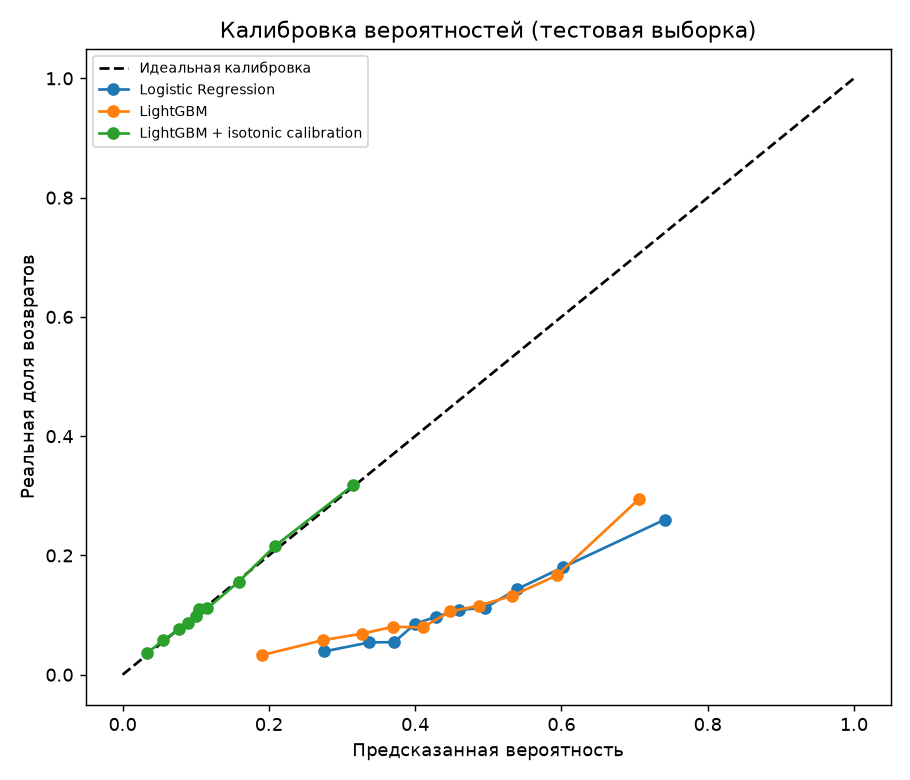

In [8]:
display(Image(filename=str(config.FIGURES_DIR / '08_calibration.png')))

In [9]:
table[['model', 'brier', 'threshold', 'roc_auc', 'pr_auc']]

,model,brier,threshold,roc_auc,pr_auc
0,Dummy (baseline),0.1006,0.5000,0.5000,0.1135
1,Logistic Regression,0.2242,0.5316,0.6728,0.2262
2,LightGBM,0.2050,0.5594,0.6806,0.2479
3,LightGBM + isotonic calibration,0.0950,0.1500,0.6785,0.2306


Чем ближе линия к диагонали, тем честнее вероятности. Некалиброванные модели лежат заметно ниже диагонали — они завышают риск. После калибровки линия ложится на диагональ, а Brier падает больше чем вдвое: с 0.205 до 0.095. Порог при этом тоже меняется: 0.15 вместо 0.56, то есть он теперь стоит рядом с реальной долей возвратов.

У калибровки есть цена: изотоническая регрессия склеивает близкие вероятности в ступеньки, поэтому PR-AUC немного снижается (0.248 → 0.231), а ROC-AUC почти не меняется (0.681 → 0.679). Мы идём на это сознательно, потому что продукт показывает пользователю именно вероятность.

Сохраняется именно калиброванная модель.

## 3.6. Матрица ошибок

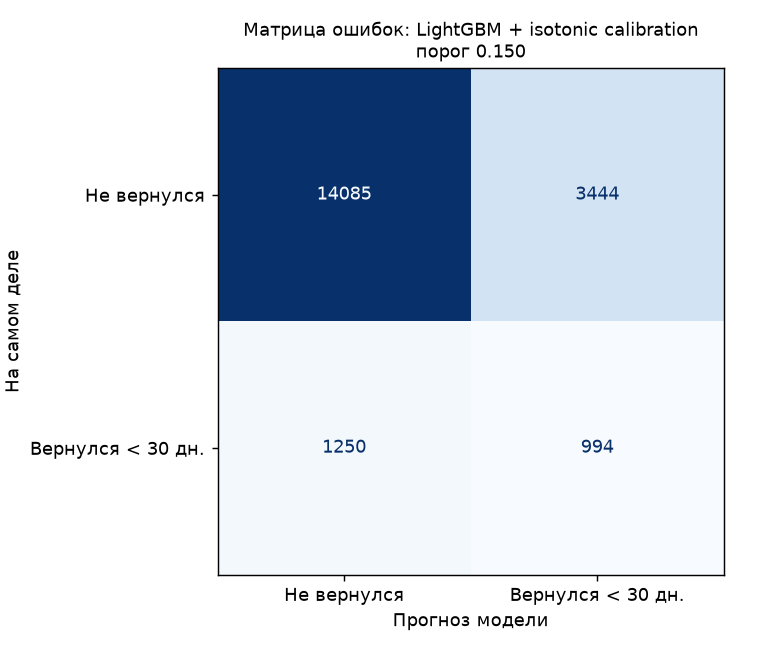

In [10]:
display(Image(filename=str(config.FIGURES_DIR / '09_confusion_matrix.png')))

В test 2 244 пациента реально вернулись раньше 30 дней:

- **994 пойманы** (правый нижний угол) — это recall 44%;
- **1 250 пропущены** (левый нижний угол): вернулись, а модель не предупредила — самая дорогая ошибка;
- **3 444 ложные тревоги** (правый верхний угол): модель предупредила, а пациент не вернулся. Из всех, кого модель назвала рискованными, реально вернулись 22% (precision).

## 3.7. Какие признаки важны

Permutation importance: перемешиваем значения одного признака и смотрим, насколько упал PR-AUC. Чем сильнее упал — тем важнее признак для модели.

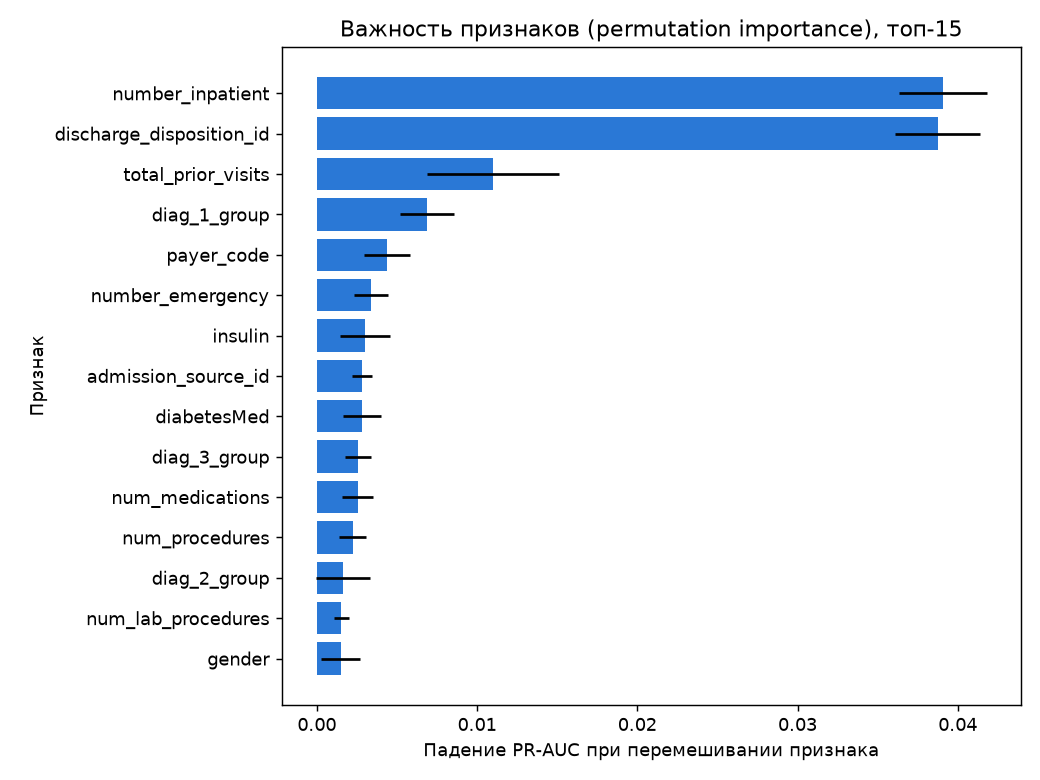

In [11]:
display(Image(filename=str(config.FIGURES_DIR / '10_feature_importance.png')))

In [12]:
pd.read_csv(config.REPORTS_DIR / 'feature_importance.csv').head(10).round(4)

,feature,importance_mean,importance_std
0,number_inpatient,0.0391,0.0027
1,discharge_disposition_id,0.0388,0.0026
2,total_prior_visits,0.0110,0.0041
3,diag_1_group,0.0069,0.0017
4,payer_code,0.0044,0.0015
5,number_emergency,0.0034,0.0010
6,insulin,0.0030,0.0016
7,admission_source_id,0.0028,0.0006
8,diabetesMed,0.0028,0.0012
9,diag_3_group,0.0026,0.0008


Это совпадает с тем, что мы видели в EDA: важнее всего история госпитализаций (`number_inpatient`) и то, куда пациента выписали (`discharge_disposition_id`).

## 3.8. Анализ ошибок

Сравниваем средние значения признаков у двух групп реально вернувшихся пациентов: тех, кого модель пропустила (FN), и тех, кого поймала (TP).

In [13]:
pd.read_csv(config.REPORTS_DIR / 'error_analysis.csv')

,group,count,number_inpatient,number_emergency,time_in_hospital,num_medications,number_diagnoses,age_num
0,"FN - пропущенные (вернулись, модель не предупр...",1250,0.31,0.14,4.48,16.39,7.53,67.10
1,"TP - пойманные (вернулись, модель предупредила)",994,2.47,0.63,4.95,17.51,7.78,64.99


Модель ловит тех, у кого уже были госпитализации и визиты в скорую. Пропускает она пациентов «без истории»: по остальным признакам (дни в больнице, число лекарств и диагнозов, возраст) они почти не отличаются от пойманных. То есть в данных просто нет сигнала, по которому таких пациентов можно было бы найти.

## 3.9. Что будет, если делить не по пациентам

`leakage_demo` обучает один и тот же LightGBM на двух разбиениях: по пациентам и случайном по строкам.

In [14]:
models.leakage_demo(clean)

,split,patients_in_both_train_and_test,roc_auc,pr_auc
0,по пациентам (правильно),0,0.6760,0.2449
1,случайно по строкам (утечка),6755,0.6779,0.2337


При случайном разбиении 6 755 пациентов оказываются и в train, и в test. На этих данных цифры двух разбиений получились близкими (ROC-AUC 0.676 и 0.678), то есть сильного завышения качества здесь не видно. Но оценка при случайном разбиении всё равно нечестная: в жизни модель будет работать с новыми пациентами, которых раньше не видела, и проверять её нужно так же.

## 3.10. Прогноз для одного пациента

`predict_patient` принимает словарь с признаками пациента и возвращает вероятность возврата. Признаки, которые не указаны, заполняются типичными значениями.

In [15]:
bundle = models.load_model()
print('Модель:', bundle['name'])
print('Порог: ', round(bundle['threshold'], 3))

Модель: LightGBM + isotonic calibration
Порог:  0.15


In [16]:
patients = {
    'Пациент А: первая госпитализация': {
        'age_num': 55, 'time_in_hospital': 3, 'num_lab_procedures': 40, 'num_procedures': 0,
        'num_medications': 10, 'number_outpatient': 0, 'number_emergency': 0, 'number_inpatient': 0,
        'number_diagnoses': 5, 'total_prior_visits': 0,
    },
    'Пациент Б: частые госпитализации': {
        'age_num': 75, 'time_in_hospital': 8, 'num_lab_procedures': 60, 'num_procedures': 2,
        'num_medications': 25, 'number_outpatient': 1, 'number_emergency': 2, 'number_inpatient': 4,
        'number_diagnoses': 9, 'total_prior_visits': 7, 'insulin': 'Up',
    },
}

for label, patient in patients.items():
    result = models.predict_patient(patient, bundle)
    risk = 'ВЫСОКИЙ' if result['high_risk'] else 'низкий'
    print(label)
    print(f'   Вероятность повторной госпитализации в течение 30 дней: {result["probability"] * 100:.1f}%')
    print(f'   Риск: {risk} (порог {result["threshold"] * 100:.1f}%)')
    print()

Пациент А: первая госпитализация
   Вероятность повторной госпитализации в течение 30 дней: 7.6%
   Риск: низкий (порог 15.0%)

Пациент Б: частые госпитализации
   Вероятность повторной госпитализации в течение 30 дней: 30.5%
   Риск: ВЫСОКИЙ (порог 15.0%)



## Выводы

1. **Обе модели заметно лучше baseline.** PR-AUC у Dummy равен 0.11 (доля возвратов), у логистической регрессии — 0.23, у LightGBM — 0.25. ROC-AUC — 0.67 и 0.68 против 0.50.
2. **LightGBM лучше логистической регрессии, но ненамного.** За это он платит размером (2.7 МБ против 0.02 МБ) и более долгим обучением. Небольшой разрыв говорит о том, что качество ограничено данными, а не моделью.
3. **Калибровка исправила вероятности:** Brier упал с 0.205 до 0.095, порог сместился с 0.56 до 0.15. Сохранена калиброванная модель LightGBM.
4. **Итоговая модель находит 44% вернувшихся** (recall 0.44) при precision 0.22: на одного найденного пациента приходится примерно три-четыре ложные тревоги.
5. **Главные признаки — история госпитализаций и тип выписки.** Пропускает модель в основном пациентов без прошлых госпитализаций: в данных нет сигнала, по которому их можно найти.
6. **Разбиение сделано по пациентам:** общих пациентов между train и test нет.

ROC-AUC около 0.68 — обычный уровень для этого датасета: в нём нет ни результатов анализов в динамике, ни сведений о том, что происходило с пациентом после выписки.